# Libraries

In [ ]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import GradientBoostingClassifier
from sklearn import tree
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score,
    classification_report
)

# Loading Datasets

In [ ]:
studentRegistration = pd.read_csv("studentRegistration.csv")
studentInfo = pd.read_csv("studentInfo.csv")
studentVle = pd.read_csv("studentVle.csv")
studentAssessment = pd.read_csv("studentAssessment.csv")
courses = pd.read_csv("courses.csv")
vle = pd.read_csv("vle.csv")
assessments = pd.read_csv("assessments.csv")

# Missing Value

In [ ]:
studentRegistration.isnull().sum()[studentRegistration.isnull().sum() > 0]

date_registration         45
date_unregistration    22521
dtype: int64

In [ ]:
studentInfo.isnull().sum()[studentInfo.isnull().sum() > 0]

imd_band    1111
dtype: int64

In [ ]:
studentVle.isnull().sum()[studentVle.isnull().sum() > 0]

Series([], dtype: int64)

In [ ]:
studentAssessment.isnull().sum()[studentAssessment.isnull().sum() > 0]

score    173
dtype: int64

In [ ]:
courses.isnull().sum()[courses.isnull().sum() > 0]

Series([], dtype: int64)

In [ ]:
vle.isnull().sum()[vle.isnull().sum() > 0]

week_from    5243
week_to      5243
dtype: int64

In [ ]:
assessments.isnull().sum()[assessments.isnull().sum() > 0]

date    11
dtype: int64

# Cleaning Data

In [ ]:
#Assuming missing registration are around the others registration period
studentRegistration["date_registration"] = studentRegistration["date_registration"].fillna(studentRegistration["date_registration"].median())

#Missing values shows no withdrawal with positive value shows withdrew at some point
studentRegistration["date_unregistration"] = studentRegistration["date_unregistration"].fillna(-1)

#Fills with most common category
studentInfo["imd_band"] = studentInfo["imd_band"].fillna(studentInfo["imd_band"].mode()[0])

#Value -1 indicates absence of a defined time window
vle["week_from"] = vle["week_from"].fillna(-1)
vle["week_to"] = vle["week_to"].fillna(-1)

#Missing scores as non-submission, i.e lack of performance
studentAssessment["score"] = studentAssessment["score"].fillna(0)

#Keeping values within a realistic timeline
assessments["date"] = assessments["date"].fillna(assessments["date"].median())

# Merging Datasets

In [ ]:
finalMerge = studentInfo.copy()

In [ ]:
#Merging the student registration
finalMerge = finalMerge.merge(
    studentRegistration,
    on=["id_student", "code_module", "code_presentation"],
    how="left"
)

In [ ]:
#This is the first-half assessment features
#Merge studentAssessment with assessments table
assessment_merged = studentAssessment.merge(
    assessments,
    on="id_assessment",
    how="left"
)

# Merge in course length
assessment_merged = assessment_merged.merge(
    courses,
    on=["code_module", "code_presentation"],
    how="left"
)

#Handle missing values
assessment_merged["date"] = assessment_merged["date"].fillna(
    assessment_merged["date"].median()
)
assessment_merged["score"] = assessment_merged["score"].fillna(0)

#Compute halfway point
assessment_merged["halfway_point"] = (
    assessment_merged["module_presentation_length"] / 2
)

#Keep only assessments in first half of the course
assessment_first_half = assessment_merged[
    assessment_merged["date"] <= assessment_merged["halfway_point"]
].copy()

In [ ]:
#Aggregating the first half assessment
assessment_agg = assessment_first_half.groupby(
    ["id_student", "code_module", "code_presentation"]
).agg(
    score=("score", "mean"),
    weight=("weight", "sum")
).reset_index()

In [ ]:
#Merging first half assessment into final Merge
finalMerge = finalMerge.merge(
    assessment_agg,
    on=["id_student", "code_module", "code_presentation"],
    how="left"
)

In [ ]:
#Same thing with the studentAssesment above

In [ ]:
#Merge studentVle with course length
vle_merged = studentVle.merge(
    courses,
    on=["code_module", "code_presentation"],
    how="left"
)

#Compute halfway point
vle_merged["halfway_point"] = (
    vle_merged["module_presentation_length"] / 2
)

#Keep only VLE activity in first half of the course
vle_first_half = vle_merged[
    vle_merged["date"] <= vle_merged["halfway_point"]
].copy()

In [ ]:
vle_agg = vle_first_half.groupby(
    ["id_student", "code_module", "code_presentation"]
).agg(
    sum_click=("sum_click", "sum")
).reset_index()

In [ ]:
finalMerge = finalMerge.merge(
    vle_agg,
    on=["id_student", "code_module", "code_presentation"],
    how="left"
)

In [ ]:
finalMerge = finalMerge.merge(
    courses,
    on=["code_module", "code_presentation"],
    how="left"
)

In [ ]:
finalMerge.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,date_registration,date_unregistration,score,weight,sum_click,module_presentation_length
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,-159.0,-1.0,81.000000,50.0,710.0,268
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,-53.0,-1.0,69.333333,50.0,986.0,268
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,-92.0,12.0,NaN,NaN,281.0,268
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,-52.0,-1.0,72.333333,50.0,1382.0,268
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,-176.0,-1.0,54.000000,50.0,799.0,268


# Handling Missing Values after Merging

In [ ]:
finalMerge.isnull().sum()[finalMerge.isnull().sum() > 0]

score        6795
weight       6795
sum_click    3389
dtype: int64

In [ ]:
finalMerge["date_registration"] = finalMerge["date_registration"].fillna(
    finalMerge["date_registration"].median()
)

finalMerge["date_unregistration"] = finalMerge["date_unregistration"].fillna(-1)
#In schema it mentions "If the student does not submit the assessment, no result is recorded", going to assume student did not submit assignment
finalMerge["score"] = finalMerge["score"].fillna(0)
finalMerge["weight"] = finalMerge["weight"].fillna(0)
finalMerge["sum_click"] = finalMerge["sum_click"].fillna(0)

In [ ]:
finalMerge.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,date_registration,date_unregistration,score,weight,sum_click,module_presentation_length
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,-159.0,-1.0,81.000000,50.0,710.0,268
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,-53.0,-1.0,69.333333,50.0,986.0,268
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,-92.0,12.0,0.000000,0.0,281.0,268
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,-52.0,-1.0,72.333333,50.0,1382.0,268
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,-176.0,-1.0,54.000000,50.0,799.0,268


In [ ]:
finalMerge.isnull().sum()[finalMerge.isnull().sum() > 0]

Series([], dtype: int64)

# Duplicate (Using the latest Student Data)

In [ ]:
#Sorting the Presentation to seperate components i.e 2024, J
finalMerge["presentation_year"] = finalMerge["code_presentation"].str[:4].astype(int)
finalMerge["presentation_session"] = finalMerge["code_presentation"].str[4]

#B means Earlier and J means Later
session_order = {"B": 0, "J": 1}
finalMerge["presentation_session_order"] = finalMerge["presentation_session"].map(session_order)

#Sort so latest attempt comes last
finalMerge = finalMerge.sort_values(
    by=["id_student", "code_module", "presentation_year", "presentation_session_order"]
)

#Keeping only the latest attempt for each student and module pair
finalMerge = finalMerge.drop_duplicates(
    subset=["id_student", "code_module"],
    keep="last"
)

In [ ]:
print(finalMerge["final_result"].value_counts())

final_result
Pass           12356
Withdrawn       8962
Fail            6942
Distinction     3024
Name: count, dtype: int64


In [ ]:
finalMerge.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,...,final_result,date_registration,date_unregistration,score,weight,sum_click,module_presentation_length,presentation_year,presentation_session,presentation_session_order
14394,DDD,2013J,3733,M,South Region,HE Qualification,90-100%,55<=,0,60,...,Withdrawn,-68.0,-8.0,0.0,0.0,0.0,261,2013,J,1
383,AAA,2014J,6516,M,Scotland,HE Qualification,80-90%,55<=,0,60,...,Pass,-52.0,-1.0,57.0,50.0,1603.0,269,2014,J,1
17560,DDD,2014J,8462,M,London Region,HE Qualification,30-40%,55<=,1,60,...,Withdrawn,-38.0,18.0,86.5,50.0,10.0,262,2014,J,1
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,...,Pass,-159.0,-1.0,81.0,50.0,710.0,268,2013,J,1
748,BBB,2013B,23629,F,East Anglian Region,Lower Than A Level,20-30%,0-35,2,60,...,Fail,-47.0,-1.0,82.5,25.0,161.0,240,2013,B,0


In [ ]:
#Dropping columns to reduce noise, as its used to handle duplicates
finalMerge = finalMerge.drop(columns=["presentation_year", "presentation_session", "presentation_session_order"])

In [ ]:
finalMerge.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,date_registration,date_unregistration,score,weight,sum_click,module_presentation_length
14394,DDD,2013J,3733,M,South Region,HE Qualification,90-100%,55<=,0,60,N,Withdrawn,-68.0,-8.0,0.0,0.0,0.0,261
383,AAA,2014J,6516,M,Scotland,HE Qualification,80-90%,55<=,0,60,N,Pass,-52.0,-1.0,57.0,50.0,1603.0,269
17560,DDD,2014J,8462,M,London Region,HE Qualification,30-40%,55<=,1,60,N,Withdrawn,-38.0,18.0,86.5,50.0,10.0,262
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,-159.0,-1.0,81.0,50.0,710.0,268
748,BBB,2013B,23629,F,East Anglian Region,Lower Than A Level,20-30%,0-35,2,60,N,Fail,-47.0,-1.0,82.5,25.0,161.0,240


In [ ]:
finalMerge = finalMerge.drop(columns=[
    "date_registration",
    "date_unregistration"
])

In [ ]:
finalMerge.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,score,weight,sum_click,module_presentation_length
14394,DDD,2013J,3733,M,South Region,HE Qualification,90-100%,55<=,0,60,N,Withdrawn,0.0,0.0,0.0,261
383,AAA,2014J,6516,M,Scotland,HE Qualification,80-90%,55<=,0,60,N,Pass,57.0,50.0,1603.0,269
17560,DDD,2014J,8462,M,London Region,HE Qualification,30-40%,55<=,1,60,N,Withdrawn,86.5,50.0,10.0,262
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,81.0,50.0,710.0,268
748,BBB,2013B,23629,F,East Anglian Region,Lower Than A Level,20-30%,0-35,2,60,N,Fail,82.5,25.0,161.0,240


In [ ]:
print(finalMerge["final_result"].value_counts())

final_result
Pass           12356
Withdrawn       8962
Fail            6942
Distinction     3024
Name: count, dtype: int64


# Feature Engineering

In [ ]:
finalMergeBC = finalMerge.copy()

In [ ]:
#Binary

In [ ]:
finalMergeBC["final_result_binary"] = finalMergeBC["final_result"].map({
    "Distinction": 1,
    "Pass": 1,
    "Fail": 0,
    "Withdrawn": 0
})
finalMergeBC.drop("final_result", axis=1, inplace=True)

In [ ]:
finalMergeBC["disability_binary"] = finalMergeBC["disability"].map({
    "Y": 1,
    "N": 0,
})
finalMergeBC.drop("disability", axis=1, inplace=True)

In [ ]:
finalMergeBC["gender_binary"] = finalMergeBC["gender"].map({
    "M": 1,
    "F": 0,
})
finalMergeBC.drop("gender", axis=1, inplace=True)

In [ ]:
#Ordinal

In [ ]:
education_map = {
    "No Formal quals": 0,
    "Lower Than A Level": 1,
    "A Level or Equivalent": 2,
    "HE Qualification": 3,
    "Post Graduate Qualification": 4
}

finalMergeBC["highest_education"] = finalMergeBC["highest_education"].map(education_map)

In [ ]:
finalMergeBC.isnull().sum()[finalMergeBC.isnull().sum() > 0]

Series([], dtype: int64)

In [ ]:
imd_map = {
    "0-10%": 0,
    "0-10": 0,
    "10-20%": 1,
    "10-20": 1,
    "20-30%": 2,
    "20-30": 2,
    "30-40%": 3,
    "30-40": 3,
    "40-50%": 4,
    "40-50": 4,
    "50-60%": 5,
    "50-60": 5,
    "60-70%": 6,
    "60-70": 6,
    "70-80%": 7,
    "70-80": 7,
    "80-90%": 8,
    "80-90": 8,
    "90-100%": 9,
    "90-100": 9
}

finalMergeBC["imd_band"] = finalMergeBC["imd_band"].map(imd_map)

In [ ]:
age_map = {
    "0-35": 0,
    "35-55": 1,
    "55<=": 2
}

finalMergeBC["age_band"] = finalMergeBC["age_band"].map(age_map)

In [ ]:
# One-hot Encoding

In [ ]:
finalMergeBC = pd.get_dummies(
    finalMergeBC,
    columns=["code_module", "code_presentation", "region"]
)

In [ ]:
#Dealing with the data leakage otherwise too high of accuraccy, days_active decided to remove as it users future data which can cause leakage

In [ ]:
finalMergeBC = finalMergeBC.drop(columns="id_student")

In [ ]:
finalMergeBC.head()

,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,score,weight,sum_click,module_presentation_length,final_result_binary,...,region_London Region,region_North Region,region_North Western Region,region_Scotland,region_South East Region,region_South Region,region_South West Region,region_Wales,region_West Midlands Region,region_Yorkshire Region
14394,3,9,2,0,60,0.0,0.0,0.0,261,0,...,False,False,False,False,False,True,False,False,False,False
383,3,8,2,0,60,57.0,50.0,1603.0,269,1,...,False,False,False,True,False,False,False,False,False,False
17560,3,3,2,1,60,86.5,50.0,10.0,262,0,...,True,False,False,False,False,False,False,False,False,False
0,3,9,2,0,240,81.0,50.0,710.0,268,1,...,False,False,False,False,False,False,False,False,False,False
748,1,2,0,2,60,82.5,25.0,161.0,240,0,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
list(finalMergeBC.columns)

['highest_education',
 'imd_band',
 'age_band',
 'num_of_prev_attempts',
 'studied_credits',
 'score',
 'weight',
 'sum_click',
 'module_presentation_length',
 'final_result_binary',
 'disability_binary',
 'gender_binary',
 'code_module_AAA',
 'code_module_BBB',
 'code_module_CCC',
 'code_module_DDD',
 'code_module_EEE',
 'code_module_FFF',
 'code_module_GGG',
 'code_presentation_2013B',
 'code_presentation_2013J',
 'code_presentation_2014B',
 'code_presentation_2014J',
 'region_East Anglian Region',
 'region_East Midlands Region',
 'region_Ireland',
 'region_London Region',
 'region_North Region',
 'region_North Western Region',
 'region_Scotland',
 'region_South East Region',
 'region_South Region',
 'region_South West Region',
 'region_Wales',
 'region_West Midlands Region',
 'region_Yorkshire Region']

In [ ]:
finalMergeBC.isnull().sum()[finalMergeBC.isnull().sum() > 0]

Series([], dtype: int64)

# Train and Test

In [ ]:
X = finalMergeBC.drop("final_result_binary", axis=1)
y = finalMergeBC["final_result_binary"]

X_trainC, X_testC, y_trainC, y_testC = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

featureList = X_trainC.columns

scaler = StandardScaler()

X_trainC = scaler.fit_transform(X_trainC)
X_testC = scaler.transform(X_testC)

In [ ]:
#Random Forest

In [ ]:
rfModel = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    random_state=42
)

rfModel.fit(X_trainC, y_trainC)

RandomForestClassifier(n_estimators=200, random_state=42)

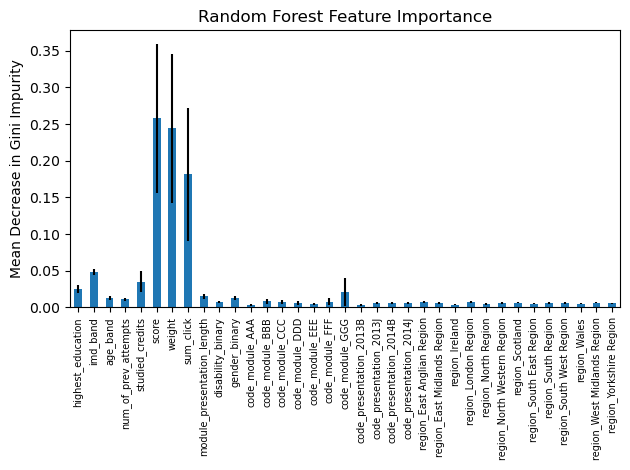

In [ ]:
importance = rfModel.feature_importances_
std = np.std([tree.feature_importances_ for tree in rfModel.estimators_], axis=0)

forestImportance = pd.Series(importance, index=featureList)

fig, ax = plt.subplots()
forestImportance.plot.bar(yerr=std, ax=ax)
ax.set_title("Random Forest Feature Importance")
ax.set_ylabel("Mean Decrease in Gini Impurity")
ax.tick_params(axis='x', labelsize=7)
fig.tight_layout()

In [ ]:
y_pred_rf = rfModel.predict(X_testC)
y_prob_rf = rfModel.predict_proba(X_testC)[:, 1]

In [ ]:
acc_rf = accuracy_score(y_testC, y_pred_rf)
prec_rf = precision_score(y_testC, y_pred_rf)
rec_rf = recall_score(y_testC, y_pred_rf)
f1_rf = f1_score(y_testC, y_pred_rf)

print("Random Forest Performance:")
print("--------------------------")
print("Accuracy :", acc_rf)
print("Precision:", prec_rf)
print("Recall   :", rec_rf)
print("F1-score :", f1_rf)

Random Forest Performance:
--------------------------
Accuracy : 0.8716637366149912
Precision: 0.8387481371087928
Recall   : 0.9148244473342002
F1-score : 0.8751360597107759


In [ ]:
print(confusion_matrix(y_testC, y_pred_rf))

[[2640  541]
 [ 262 2814]]


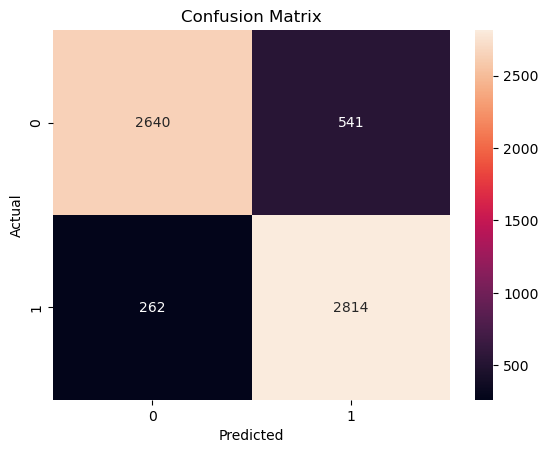

In [ ]:
RFcm = confusion_matrix(y_testC, y_pred_rf)

plt.figure()
sns.heatmap(RFcm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

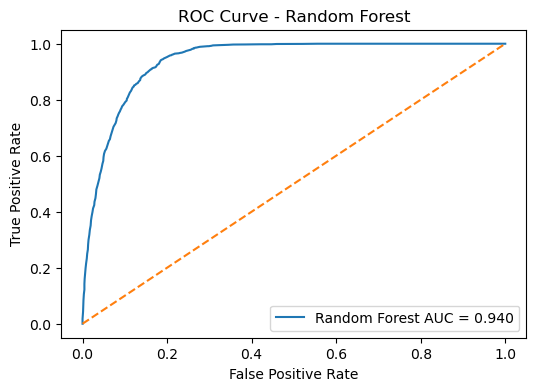

In [ ]:
fpr, tpr, thresholds = roc_curve(y_testC, y_prob_rf)
aucScore = roc_auc_score(y_testC, y_prob_rf)

plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f"Random Forest AUC = {aucScore:.3f}")
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.show()

In [ ]:
#Decision Tree

In [ ]:
dtModel = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)
dtModel.fit(X_trainC, y_trainC)

DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, min_samples_split=10,
                       random_state=42)

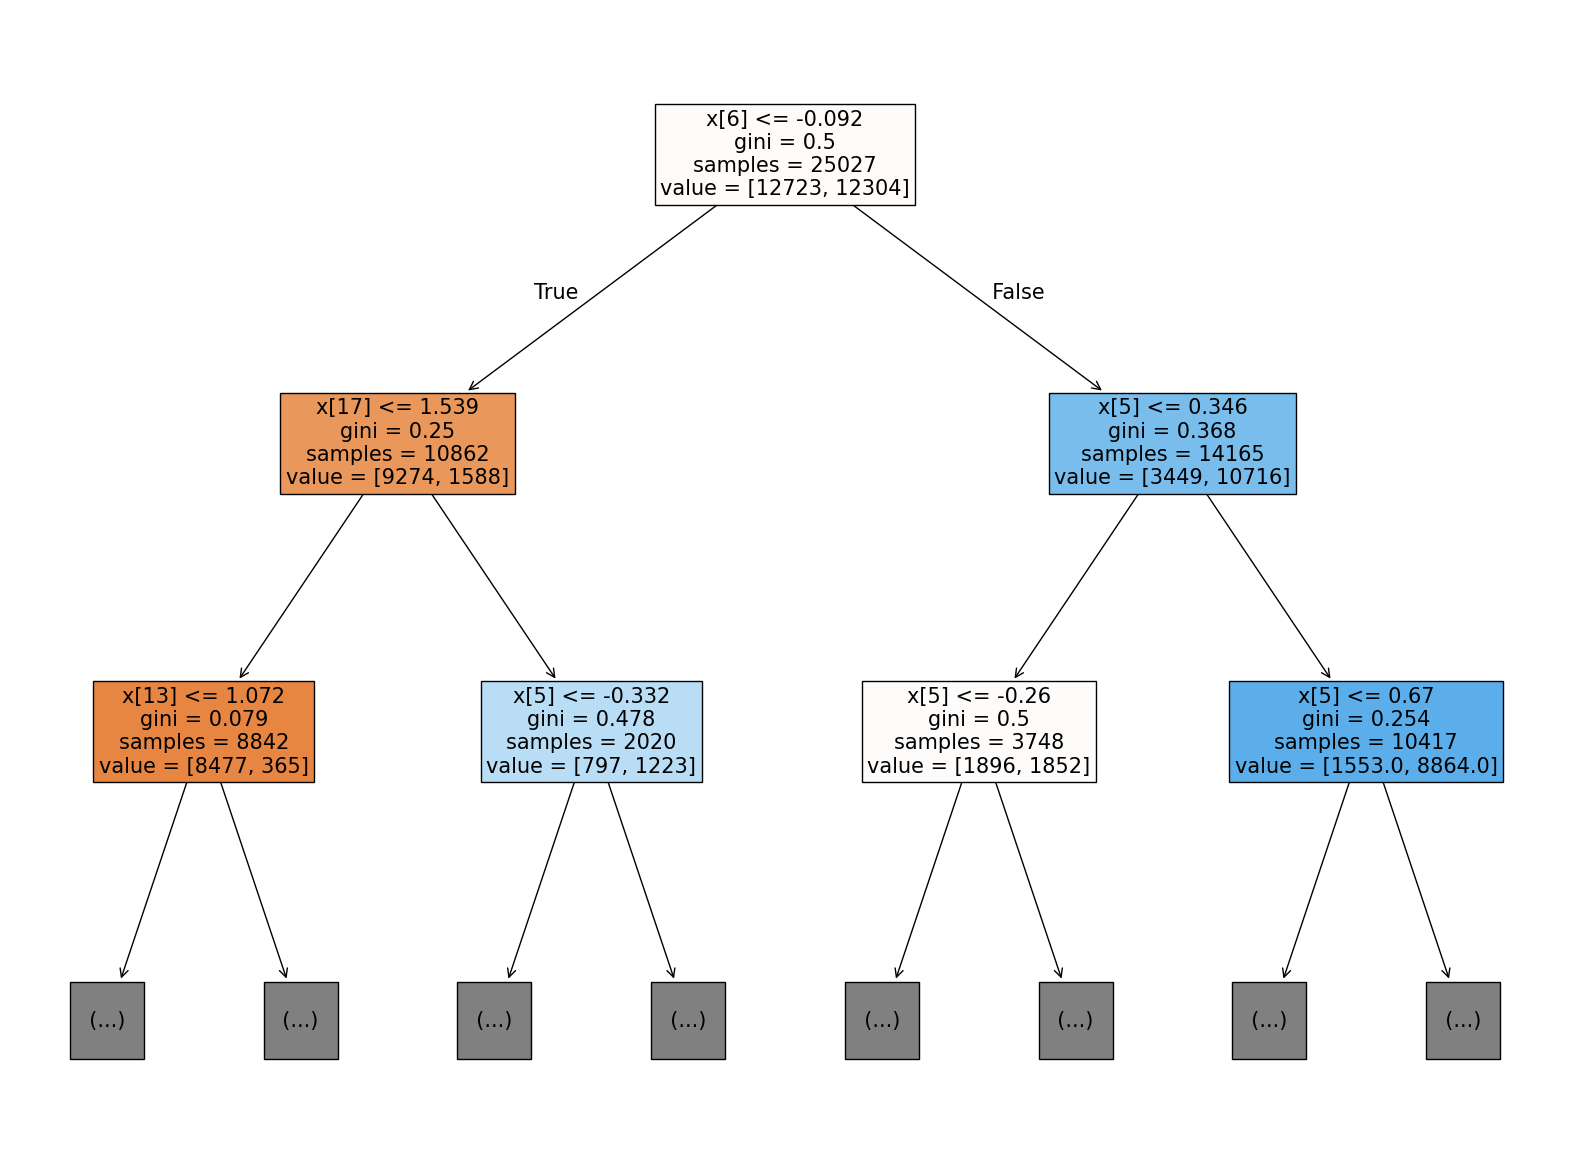

In [ ]:
plt.figure(figsize=(20,15))
tree.plot_tree(dtModel, filled=True, max_depth=2, fontsize= 15)
plt.show()

In [ ]:
y_pred_dt = dtModel.predict(X_testC)
y_prob_dt = dtModel.predict_proba(X_testC)[:, 1]

In [ ]:
acc_dt = accuracy_score(y_testC, y_pred_dt)
prec_dt = precision_score(y_testC, y_pred_dt)
rec_dt = recall_score(y_testC, y_pred_dt)
f1_dt = f1_score(y_testC, y_pred_dt)

print("Decision Tree Performance:")
print("-------------------------------")
print("Accuracy :", acc_dt)
print("Precision:", prec_dt)
print("Recall   :", rec_dt)
print("F1-score :", f1_dt)

Decision Tree Performance:
-------------------------------
Accuracy : 0.855361994566086
Precision: 0.8363805392004958
Recall   : 0.8774382314694408
F1-score : 0.8564175789306679


In [ ]:
print(confusion_matrix(y_testC, y_pred_dt))

[[2653  528]
 [ 377 2699]]


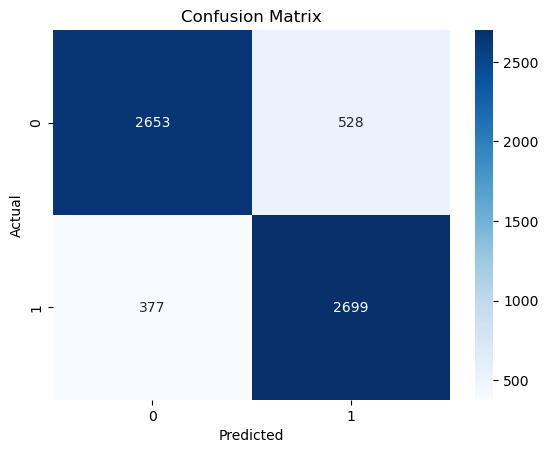

In [ ]:
DTcm = confusion_matrix(y_testC, y_pred_dt)

plt.figure()
sns.heatmap(DTcm, annot=True, fmt='d', cmap = "Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

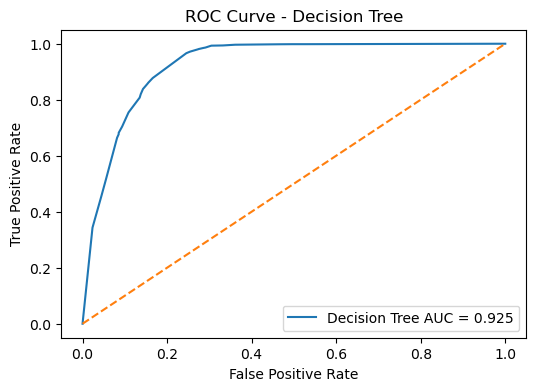

In [ ]:
fpr, tpr, thresholds = roc_curve(y_testC, y_prob_dt)
aucScore = roc_auc_score(y_testC, y_prob_dt)

plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f"Decision Tree AUC = {aucScore:.3f}")
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Decision Tree")
plt.legend()
plt.show()

In [ ]:
#Gradient Boosting

In [ ]:
gbModel = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gbModel.fit(X_trainC, y_trainC)

GradientBoostingClassifier(random_state=42)

In [ ]:
y_pred_gb = gbModel.predict(X_testC)
y_prob_gb = gbModel.predict_proba(X_testC)[:, 1]

In [ ]:
acc_gb = accuracy_score(y_testC, y_pred_gb)
prec_gb = precision_score(y_testC, y_pred_gb)
rec_gb = recall_score(y_testC, y_pred_gb)
f1_gb = f1_score(y_testC, y_pred_gb)

print("Gradient Boosting Performance:")
print("-------------------------------")
print("Accuracy :", acc_gb)
print("Precision:", prec_gb)
print("Recall   :", rec_gb)
print("F1-score :", f1_gb)

Gradient Boosting Performance:
-------------------------------
Accuracy : 0.8759789036279367
Precision: 0.8394332939787486
Recall   : 0.9245773732119635
F1-score : 0.879950495049505


In [ ]:
print(confusion_matrix(y_testC, y_pred_gb))

[[2637  544]
 [ 232 2844]]


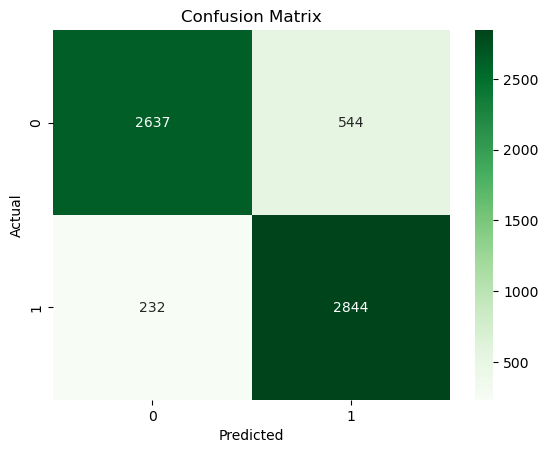

In [ ]:
GBcm = confusion_matrix(y_testC, y_pred_gb)

plt.figure()
sns.heatmap(GBcm, annot=True, fmt='d', cmap = "Greens")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

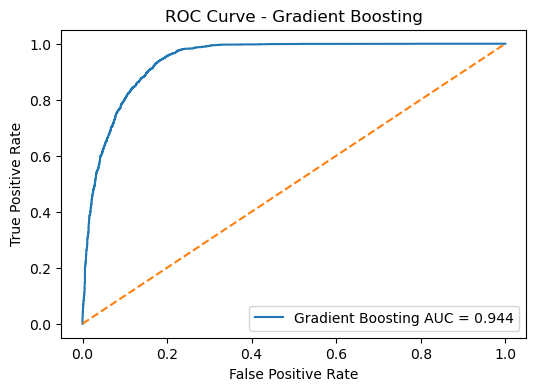

In [ ]:
fpr, tpr, thresholds = roc_curve(y_testC, y_prob_gb)
aucScore = roc_auc_score(y_testC, y_prob_gb)

plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f"Gradient Boosting AUC = {aucScore:.3f}")
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Gradient Boosting")
plt.legend()
plt.show()

In [ ]:
#Logistic Regression

In [ ]:
logModel = LogisticRegression(max_iter=1000)
logModel.fit(X_trainC, y_trainC)

LogisticRegression(max_iter=1000)

In [ ]:
y_pred_log = logModel.predict(X_testC)
y_prob_log = logModel.predict_proba(X_testC)[:, 1]

In [ ]:
acc_lr = accuracy_score(y_testC, y_pred_log)
prec_lr = precision_score(y_testC, y_pred_log)
rec_lr = recall_score(y_testC, y_pred_log)
f1_lr = f1_score(y_testC, y_pred_log)

print("Logistic Regression Performance:")
print("-------------------------------")
print("Accuracy :", acc_lr)
print("Precision:", prec_lr)
print("Recall   :", rec_lr)
print("F1-score :", f1_lr)

Logistic Regression Performance:
-------------------------------
Accuracy : 0.855361994566086
Precision: 0.8186087466979748
Recall   : 0.9066970091027308
F1-score : 0.8604041338886318


In [ ]:
print(confusion_matrix(y_testC, y_pred_log))

[[2563  618]
 [ 287 2789]]


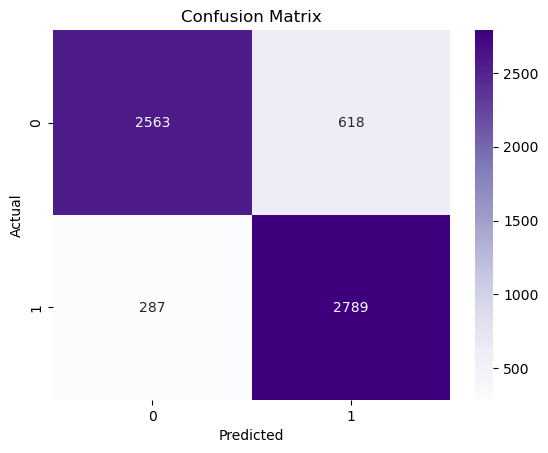

In [ ]:
LRcm = confusion_matrix(y_testC, y_pred_log)

plt.figure()
sns.heatmap(LRcm, annot=True, fmt='d', cmap = "Purples")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

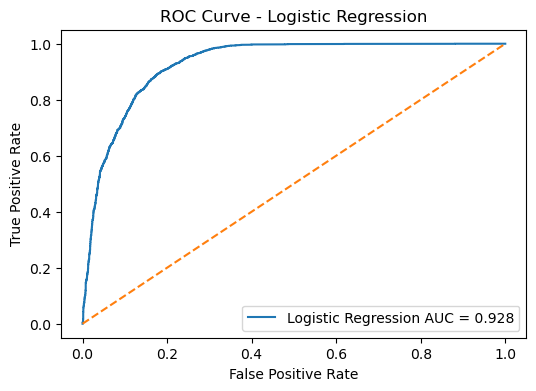

In [ ]:
fpr, tpr, thresholds = roc_curve(y_testC, y_prob_log)
aucScore = roc_auc_score(y_testC, y_prob_log)

plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f"Logistic Regression AUC = {aucScore:.3f}")
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()

In [ ]:
#K-Nearest Neighbour (KNN)

In [ ]:
knnModel = KNeighborsClassifier(n_neighbors=5)
knnModel.fit(X_trainC, y_trainC)

KNeighborsClassifier()

In [ ]:
y_pred_knn = knnModel.predict(X_testC)
y_prob_knn = knnModel.predict_proba(X_testC)[:, 1]

In [ ]:
acc_knn = accuracy_score(y_testC, y_pred_knn)
prec_knn = precision_score(y_testC, y_pred_knn)
rec_knn = recall_score(y_testC, y_pred_knn)
f1_knn = f1_score(y_testC, y_pred_knn)

print("K-Nearest Neighbour Performance:")
print("-------------------------------")
print("Accuracy :", acc_knn)
print("Precision:", prec_knn)
print("Recall   :", rec_knn)
print("F1-score :", f1_knn)

K-Nearest Neighbour Performance:
-------------------------------
Accuracy : 0.781844334345533
Precision: 0.743801652892562
Recall   : 0.8485045513654096
F1-score : 0.7927107061503417


In [ ]:
print(confusion_matrix(y_testC, y_pred_knn))

[[2282  899]
 [ 466 2610]]


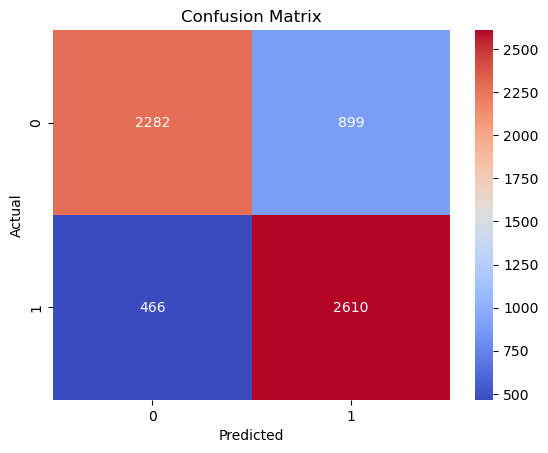

In [ ]:
knncm = confusion_matrix(y_testC, y_pred_knn)

plt.figure()
sns.heatmap(knncm, annot=True, fmt='d', cmap = "coolwarm")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

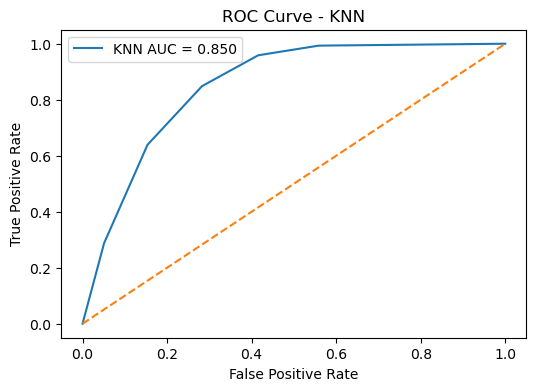

In [ ]:
fpr, tpr, thresholds = roc_curve(y_testC, y_prob_knn)
aucScore = roc_auc_score(y_testC, y_prob_knn)

plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f"KNN AUC = {aucScore:.3f}")
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - KNN")
plt.legend()
plt.show()

In [ ]:
#Support Vector Machine (SVM)

In [ ]:
svmModel = SVC(kernel="rbf", probability=True, random_state=42)
svmModel.fit(X_trainC, y_trainC)

SVC(probability=True, random_state=42)

In [ ]:
y_pred_svm = svmModel.predict(X_testC)
y_prob_svm = svmModel.predict_proba(X_testC)[:, 1]

In [ ]:
acc_svm = accuracy_score(y_testC, y_pred_svm)
prec_svm = precision_score(y_testC, y_pred_svm)
rec_svm = recall_score(y_testC, y_pred_svm)
f1_svm = f1_score(y_testC, y_pred_svm)

print("Support Vector Machine Performance:")
print("-------------------------------")
print("Accuracy :", acc_svm)
print("Precision:", prec_svm)
print("Recall   :", rec_svm)
print("F1-score :", f1_svm)

Support Vector Machine Performance:
-------------------------------
Accuracy : 0.8679878536039636
Precision: 0.8144214645053103
Recall   : 0.947334200260078
F1-score : 0.8758641418695522


In [ ]:
print(confusion_matrix(y_testC, y_pred_svm))

[[2517  664]
 [ 162 2914]]


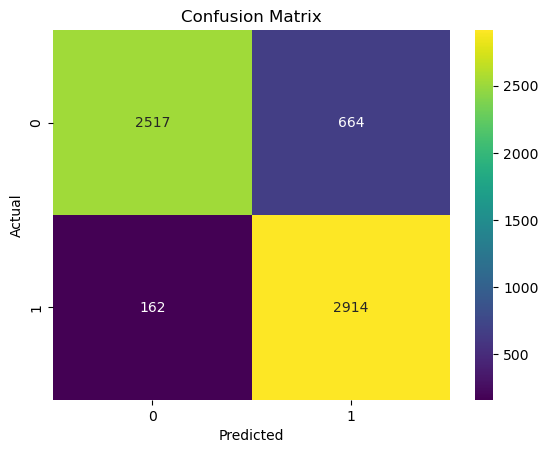

In [ ]:
SVMcm = confusion_matrix(y_testC, y_pred_svm)

plt.figure()
sns.heatmap(SVMcm, annot=True, fmt='d', cmap = "viridis")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

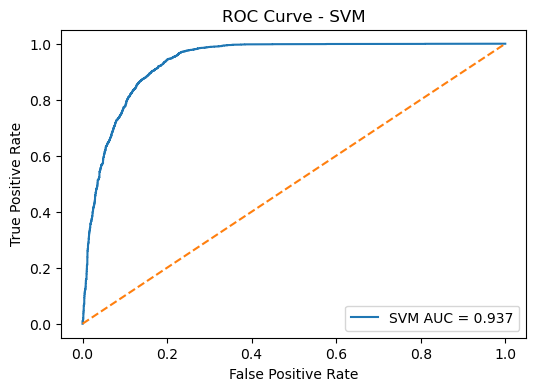

In [ ]:
fpr, tpr, thresholds = roc_curve(y_testC, y_prob_svm)
aucScore = roc_auc_score(y_testC, y_prob_svm)

plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f"SVM AUC = {aucScore:.3f}")
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - SVM")
plt.legend()
plt.show()